# DS 3000 — Project Phase II: Proof of Concept


## 1. Central motivation and research questions

High streamflow can transport sediment and other material into waterways, dilute dissolved ions, and change stream temperature and oxygen conditions. These responses can differ depending on land use, hydrology, local infrastructure, and season. Understanding patterns in real monitoring records can inform river management and help identify conditions associated with water-quality changes.

**Research question 1:** How do water-quality indicators differ between high-flow and normal-flow at monitoring stations?  
**Research question 2:** How do those high-flow-related differences compare between an urban-influenced watershed and a largely forested/rural watershed?

We examine **turbidity**, **specific conductance**, **dissolved oxygen**, **pH**, and **water temperature** when daily measurements are available. We use streamflow to identify high-flow days. Indicators must be interpreted separately: for example, lower conductance during a storm can indicate dilution; higher turbidity can indicate sediment transport. This proof of concept demonstrates descriptive association, **not causation**.

**Scope:** With only two sites, this is an exploratory comparison of these two streams, not evidence about urban and rural watersheds in general.Classifications below are provisional until supported by watershed land-cover measurements. We do **not** label high-flow percentile days as independently verified floods.

## 2. Data sources and processing pipeline

**USGS Water Data OGC API** — [official documentation](https://api.waterdata.usgs.gov/docs/ogcapi/), using its `daily` and `time-series-metadata` collections:

- **USGS-01435000:** Neversink River near Claryville, NY — **rural/forested candidate**. We checked the 2025 series IDs for discharge, water temperature, and conductance by hand. Some temperature series here come from piezometers (groundwater wells), so we exclude those.
- **USGS-01648010:** Rock Creek at Joyce Road, Washington, DC — **urban-influenced candidate**. This station has multiple types of continuous observations in its published record; Its 2025 record has daily streamflow but no daily water-quality data. Reservoirs upstream can alter its flow response.

### Reproducible pipeline
1. Query *daily-mean* (`statistic_id = 00003`) observations and time-series metadata for streamflow (`00060`), water temperature (`00010`), conductance (`00095`), turbidity (`63680`), dissolved oxygen (`00300`), and pH (`00400`).
2. Pick one in-channel series per site and indicator, and record which one was picked and why. Groundwater readings are never mixed with channel readings.
3. Parse dates and numeric values, check units, retain measurement identity, reject conflicting duplicate daily values in a selected series, and leave absent observations missing (not zero or interpolated).
4. Merge on **station + date** into one row per station-day. Calculate high/normal/low streamflow cutoffs using **all available discharge days per station** (bottom 25%, middle 50%, top 25%).
5. For each water-quality indicator, use only dates with **both** that indicator and streamflow. Calculate counts and distribution statistics by station and flow category. Don't require every indicator to exist on every date.

The monitoring period and sensor choices should be approved by the team/TA. Adding more stations with land-cover data (and ideally rainfall) would help in a later phase, but it isn’t needed for Phase II.

In [ ]:
# 3A. Imports, settings, and output folders
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE = "https://api.waterdata.usgs.gov/ogcapi/v1/collections"
START_DATE, END_DATE = "2025-01-01", "2025-12-31"
OUT = Path("data") / "phase2"
FIGURES = Path("figures") / "phase2"
OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# These are *candidate* watershed types, not verified percent-developed values.
SITES = {
    "USGS-01435000": {"name": "Neversink River near Claryville, NY", "area_type": "Rural candidate"},
    "USGS-01648010": {"name": "Rock Creek at Joyce Rd, Washington, DC", "area_type": "Urban-influenced candidate"},
}
PARAMETERS = {
    "streamflow": "00060",
    "water_temperature": "00010",
    "specific_conductance": "00095",
    "turbidity": "63680",
    "dissolved_oxygen": "00300",
    "ph": "00400",
}
QUALITY = [name for name in PARAMETERS if name != "streamflow"]

# User-verified 2025 channel/discharge IDs for original Neversink station.
# Other stations/indicators are discovered from metadata and checked against 2025 observations.
VERIFIED_SERIES = {
    ("USGS-01435000", "streamflow"): "ea0befb1e5684ae1a1efa98337f514ca",
    ("USGS-01435000", "water_temperature"): "f80fcea1c1f14bd095aca16f1c6f0d47",
    ("USGS-01435000", "specific_conductance"): "b990580737584dfd9bd639fe449c14f0",
}

session = requests.Session()
retries = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
                allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retries))
print("Stations:", list(SITES))
print("Parameters:", PARAMETERS)

Matplotlib is building the font cache; this may take a moment.


Stations: ['USGS-01435000', 'USGS-01648010']
Parameters: {'streamflow': '00060', 'water_temperature': '00010', 'specific_conductance': '00095', 'turbidity': '63680', 'dissolved_oxygen': '00300', 'ph': '00400'}


In [ ]:
# 3B. Fetch every page, inspect series metadata, and select one sensor per indicator

def get_collection(collection, params, max_pages=35):
    """Download all OGC collection pages, or fail rather than silently truncate."""
    url = f"{BASE}/{collection}/items"
    pieces = []
    for page in range(max_pages):
        response = session.get(url, params=params, timeout=60)
        response.raise_for_status()
        body = response.json()
        pieces.extend(item.get("properties", {}) for item in body.get("features", []))
        next_urls = [l.get("href") for l in body.get("links", [])
                     if l.get("rel") == "next" and l.get("href")]
        if not next_urls:
            return pd.DataFrame(pieces)
        url, params = next_urls[0], None
    raise RuntimeError(f"Exceeded {max_pages} pages from {collection}; results not safe to use")


def select_one_series(site, variable, metadata, observations):
    """Choose verified series or best channel/downstream candidate; audit selections."""
    if observations.empty:
        return None, "No 2025 daily values"
    if metadata.empty or "id" not in metadata.columns or "time_series_id" not in observations:
        return None, "Missing time-series metadata/identifiers"

    available = observations.groupby("time_series_id").size()
    candidates = metadata[metadata["id"].isin(available.index)].copy()
    if candidates.empty:
        return None, "No matching 2025 observations for metadata IDs"
    candidates["days"] = candidates["id"].map(available).astype(int)
    for field in ["sublocation_identifier", "web_description", "primary"]:
        if field not in candidates:
            candidates[field] = ""
    candidates["description"] = (
        candidates["sublocation_identifier"].fillna("").astype(str) + " " +
        candidates["web_description"].fillna("").astype(str)
    ).str.lower()

    # Prior hand-checked identities take priority; ensure they still occur in 2025.
    override = VERIFIED_SERIES.get((site, variable))
    if override:
        if override not in set(candidates["id"]):
            return None, f"Verified ID {override} missing in 2025 observations"
        return override, "Previously checked channel/discharge series"

    # Reject groundwater and discontinued/upstream sensor locations.
    candidates = candidates[~candidates["description"].str.contains(
        r"piezometer|groundwater|\bwell\b|mixedsw|discontinued|upstream", regex=True)]
    if candidates.empty:
        return None, "Only unsuitable/groundwater/discontinued series found"

    if variable != "streamflow":
        # Only choose when a channel/downstream candidate is identifiable.
        candidates = candidates[candidates["description"].str.contains("channel|downstream", regex=True)]
        if candidates.empty:
            return None, "No clearly identified channel/downstream series; manual review needed"
    candidates["is_primary"] = candidates["primary"].fillna("").eq("Primary").astype(int)
    candidates = candidates.sort_values(["is_primary", "days", "id"], ascending=[False, False, True])
    best = candidates.iloc[0]
    # Ambiguity: tied primary status and coverage for different series.
    ties = candidates[(candidates["is_primary"] == best["is_primary"]) &
                      (candidates["days"] == best["days"])]
    if len(ties) > 1:
        return None, "Multiple equally supported series; choose manually after metadata inspection: " + ", ".join(ties["id"])
    return best["id"], f"{best['description'].strip() or 'Unspecified'}; {best['days']} raw rows"

In [ ]:
# 3C. Retrieve, validate, and clean all candidate station / parameter pairs
# Can take several minutes due to the number of USGS requests.

def collect_data():
    selected, audit = [], []
    for site, info in SITES.items():
        print(f"\n{site}: {info['name']}")
        for variable, code in PARAMETERS.items():
            base_params = {"monitoring_location_id": site, "parameter_code": code,
                           "statistic_id": "00003", "limit": 500, "f": "json"}
            try:
                meta = get_collection("time-series-metadata", base_params.copy())
                obs_params = {**base_params, "datetime": f"{START_DATE}/{END_DATE}"}
                raw = get_collection("daily", obs_params)
                identifier, reason = select_one_series(site, variable, meta, raw)
                status, valid_days, unit = "skipped", 0, ""
                if identifier is not None:
                    part = raw[raw["time_series_id"] == identifier].copy()
                    if not {"time", "value"}.issubset(part.columns):
                        raise ValueError("Missing time/value columns")
                    # USGS daily timestamps are calendar dates; don't convert them across time zones.
                    part["date"] = pd.to_datetime(part["time"].astype(str).str[:10], errors="coerce")
                    part["value"] = pd.to_numeric(part["value"], errors="coerce")
                    part = part.dropna(subset=["date", "value"])
                    part = part[part["date"].between(START_DATE, END_DATE)]
                    if part.empty:
                        reason = "No numeric 2025 observations in selected series"
                    else:
                        units = part["unit_of_measure"].dropna().astype(str).unique().tolist() if "unit_of_measure" in part else []
                        if len(units) > 1:
                            raise ValueError(f"Multiple units within selected series: {units}")
                        unit = units[0] if units else "not provided"
                        differences = part.groupby("date")["value"].nunique()
                        if differences.gt(1).any():
                            raise ValueError("Different values for same date within one selected series")
                        part = part.drop_duplicates(subset="date")
                        part["site"] = site
                        part["site_name"] = info["name"]
                        part["area_type"] = info["area_type"]
                        part["variable"] = variable
                        part["unit"] = unit
                        selected.append(part[["site", "site_name", "area_type", "date", "variable", "value", "unit", "time_series_id"]])
                        valid_days, status = len(part), "selected"
                audit.append(dict(site=site, variable=variable, status=status, series_id=identifier or "",
                                  valid_days=valid_days, unit=unit, reason=reason,
                                  raw_series=raw["time_series_id"].nunique() if "time_series_id" in raw else 0))
                print(f"  {variable:<22} {status:<9} days={valid_days:<4} {reason}")
            except (requests.RequestException, ValueError, KeyError, TypeError) as error:
                print(f"  {variable:<22} ERROR: {error}")
                audit.append(dict(site=site, variable=variable, status="error", series_id="",
                                  valid_days=0, unit="", reason=str(error), raw_series=0))
    audit = pd.DataFrame(audit)
    audit.to_csv(OUT / "series_audit.csv", index=False)
    if not selected:
        raise RuntimeError("No usable series. Check network access or the series audit table.")
    clean_long = pd.concat(selected, ignore_index=True)
    assert not clean_long.duplicated(["site", "date", "variable"]).any(), "Duplicated clean observations"
    clean_long.to_csv(OUT / "clean_long.csv", index=False)
    return clean_long, audit

clean_long, audit = collect_data()
print("\nSeries audit:")
print(audit.to_string(index=False))


USGS-01435000: Neversink River near Claryville, NY
  streamflow             selected  days=365  Previously checked channel/discharge series
  water_temperature      selected  days=335  Previously checked channel/discharge series
  specific_conductance   selected  days=333  Previously checked channel/discharge series
  turbidity              skipped   days=0    No 2025 daily values
  dissolved_oxygen       skipped   days=0    No 2025 daily values
  ph                     skipped   days=0    No 2025 daily values

USGS-01648010: Rock Creek at Joyce Rd, Washington, DC
  streamflow             selected  days=365  Unspecified; 365 raw rows
  water_temperature      skipped   days=0    No clearly identified channel/downstream series; manual review needed
  specific_conductance   skipped   days=0    No clearly identified channel/downstream series; manual review needed
  turbidity              skipped   days=0    No clearly identified channel/downstream series; manual review needed
  dissolved_

In [ ]:
# 3D. Merge without discarding missing water-quality dates; label flow within station

def make_analysis(long_data):
    wide = long_data.pivot(index=["site", "site_name", "area_type", "date"],
                           columns="variable", values="value").reset_index()
    wide.columns.name = None
    for variable in PARAMETERS:
        if variable not in wide.columns:
            wide[variable] = np.nan
    if not wide["streamflow"].notna().any():
        raise RuntimeError("No streamflow data for either station; high-flow analysis not possible")
    wide["month"] = wide["date"].dt.month
    thresholds = (wide.dropna(subset=["streamflow"]).groupby("site")["streamflow"]
                  .quantile([0.25, 0.75]).unstack()
                  .rename(columns={0.25: "q25", 0.75: "q75"}).reset_index())
    wide = wide.merge(thresholds, on="site", how="left", validate="many_to_one")
    wide["flow_category"] = np.select(
        [wide["streamflow"] <= wide["q25"], wide["streamflow"] >= wide["q75"], wide["streamflow"].notna()],
        ["Low Flow", "High Flow", "Normal Flow"], default=None)
    wide = wide.sort_values(["site", "date"]).reset_index(drop=True)
    wide.to_csv(OUT / "analysis_station_days.csv", index=False)
    return wide, thresholds

analysis_data, thresholds = make_analysis(clean_long)
print("\nFlow thresholds based on all available station streamflow days:")
print(thresholds.to_string(index=False))
print("\nFirst rows:")
print(analysis_data.head(8).to_string(index=False))


Flow thresholds based on all available station streamflow days:
         site  q25   q75
USGS-01435000 67.9 175.0
USGS-01648010 15.6  46.7

First rows:
         site                           site_name       area_type       date  specific_conductance  streamflow  water_temperature  turbidity  dissolved_oxygen  ph  month  q25   q75 flow_category
USGS-01435000 Neversink River near Claryville, NY Rural candidate 2025-01-01                  22.0       731.0                4.0        NaN               NaN NaN      1 67.9 175.0     High Flow
USGS-01435000 Neversink River near Claryville, NY Rural candidate 2025-01-02                  23.0       491.0                2.5        NaN               NaN NaN      1 67.9 175.0     High Flow
USGS-01435000 Neversink River near Claryville, NY Rural candidate 2025-01-03                  24.0       358.0                1.5        NaN               NaN NaN      1 67.9 175.0     High Flow
USGS-01435000 Neversink River near Claryville, NY Rural candidate 2

In [ ]:
# 3E. Coverage, indicator-specific paired data, and descriptive flow summaries
coverage_rows, summary_rows = [], []
for site, part in analysis_data.groupby("site"):
    for variable in QUALITY:
        paired = part.dropna(subset=["streamflow", variable])
        coverage_rows.append({
            "site": site, "area_type": part["area_type"].iloc[0], "variable": variable,
            "all_station_days": len(part), "flow_days": int(part["streamflow"].notna().sum()),
            "quality_days": int(part[variable].notna().sum()), "paired_days": len(paired)
        })
        for category, sub in paired.groupby("flow_category"):
            summary_rows.append({
                "site": site, "area_type": part["area_type"].iloc[0], "variable": variable,
                "flow_category": category, "n": len(sub),
                "mean": sub[variable].mean(), "median": sub[variable].median(),
                "std": sub[variable].std()
            })
coverage = pd.DataFrame(coverage_rows)
summary = pd.DataFrame(summary_rows)
coverage.to_csv(OUT / "coverage.csv", index=False)
summary.to_csv(OUT / "flow_quality_summary.csv", index=False)
print("\nIndicator coverage (check paired_days):")
print(coverage.to_string(index=False))
print("\nIndicator-specific flow summaries:")
print(summary.to_string(index=False) if not summary.empty else "No paired measurements")

# A fair site-level comparison needs the *same* indicator with sufficient data at BOTH sites.
priority = ["turbidity", "specific_conductance", "dissolved_oxygen", "ph", "water_temperature"]
common_indicators = [v for v in priority if (coverage.query("variable == @v and paired_days >= 30")["site"].nunique() == len(SITES))]
print("\nIndicators with >=30 matched days at BOTH sites:", common_indicators)
if not common_indicators:
    print("CAUTION: No validated two-site quality comparison. Use single-site exploratory charts and state the limitation.")

# High-flow effect *within each station*, then compare differences across stations.
change_rows = []
for (site, indicator), group in summary.groupby(["site", "variable"]):
    by_flow = group.set_index("flow_category")
    if {"Normal Flow", "High Flow"}.issubset(by_flow.index):
        normal, high = by_flow.loc["Normal Flow", "mean"], by_flow.loc["High Flow", "mean"]
        n0, n1 = int(by_flow.loc["Normal Flow", "n"]), int(by_flow.loc["High Flow", "n"])
        change_rows.append({"site": site, "area_type": group["area_type"].iloc[0],
                            "variable": indicator, "normal_n": n0, "high_n": n1,
                            "normal_mean": normal, "high_mean": high,
                            "difference": high - normal,
                            "percent_change": 100 * (high - normal) / normal if pd.notna(normal) and normal != 0 else np.nan})
changes = pd.DataFrame(change_rows)
changes.to_csv(OUT / "high_vs_normal_change.csv", index=False)
print("\nHigh vs normal changes (per station; small counts need caution):")
print(changes.to_string(index=False) if not changes.empty else "No eligible categories")


Indicator coverage (check paired_days):
         site                  area_type             variable  all_station_days  flow_days  quality_days  paired_days
USGS-01435000            Rural candidate    water_temperature               365        365           335          335
USGS-01435000            Rural candidate specific_conductance               365        365           333          333
USGS-01435000            Rural candidate            turbidity               365        365             0            0
USGS-01435000            Rural candidate     dissolved_oxygen               365        365             0            0
USGS-01435000            Rural candidate                   ph               365        365             0            0
USGS-01648010 Urban-influenced candidate    water_temperature               365        365             0            0
USGS-01648010 Urban-influenced candidate specific_conductance               365        365             0            0
USGS-01648010 U

## 4. Visualizations

- **Figure 1 — Scatterplot:** Within-station *streamflow percentile* vs. an available quality indicator. Percentiles are calculated from **all station flow days**, not just water-quality days, so river-size differences are less misleading. The chart shows the direction and spread of possible relationships.
- **Figure 2 — Grouped boxplot:** Distribution of the same indicator across **low, normal, and high flow** for each station. This directly addresses changes during high flow and highlights spread/outliers rather than only means.


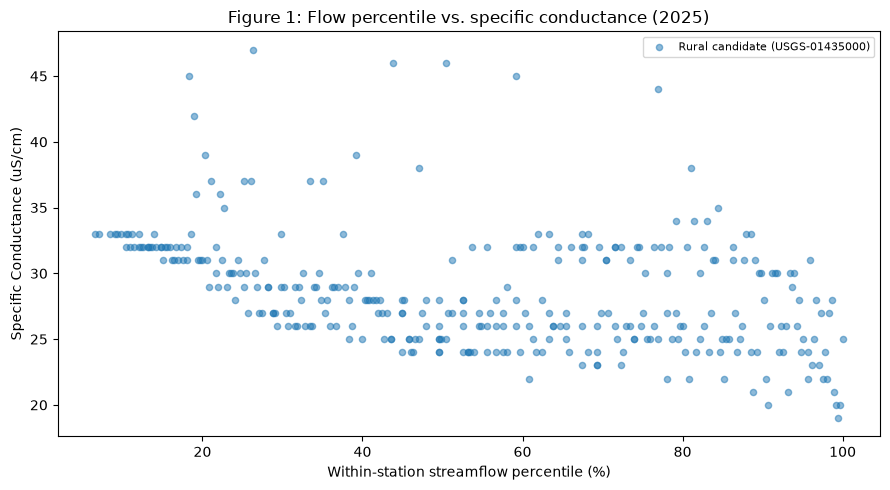

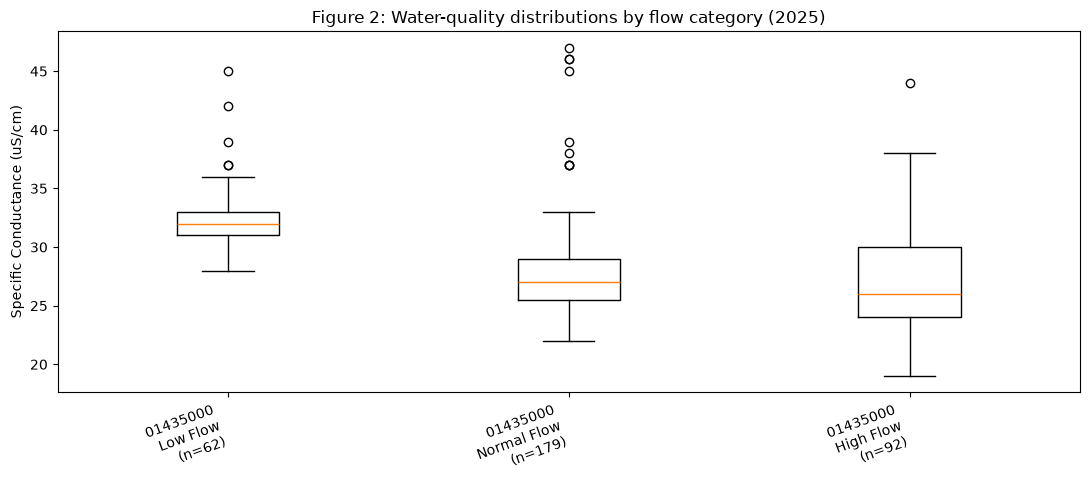

Selected indicator: specific_conductance
Both sites eligible for this indicator: False


In [ ]:
# 4A. Build charts only from measured paired data and record which indicator was used.
def choose_plot_indicator():
    for v in priority:
        if v in common_indicators:
            return v, True
    for v in priority:
        if coverage.query("variable == @v and paired_days >= 30").shape[0]:
            return v, False
    return None, False

indicator, both_sites = choose_plot_indicator()
if indicator is None:
    print("No indicator has at least 30 matching streamflow days; plots cannot be made reliably.")
else:
    plot_df = analysis_data.dropna(subset=["streamflow", indicator]).copy()
    eligible_sites = coverage.query("variable == @indicator and paired_days >= 30")["site"].tolist()
    plot_df = plot_df[plot_df["site"].isin(eligible_sites)].copy()
    # Compute within-site streamflow percentile against ALL streamflow days.
    flow_refs = {site: np.sort(g["streamflow"].dropna().to_numpy())
                 for site, g in analysis_data.groupby("site")}
    plot_df["streamflow_percentile"] = plot_df.apply(
        lambda row: 100 * np.searchsorted(flow_refs[row["site"]], row["streamflow"], side="right") /
        len(flow_refs[row["site"]]), axis=1)
    units = (audit[(audit["variable"] == indicator) & (audit["status"] == "selected")]["unit"]
             .dropna().unique().tolist())
    unit_label = units[0] if len(units) == 1 else ", ".join(units) or "see audit"
    if len(units) > 1:
        print("CAUTION: Units differ across stations. Verify compatibility before comparing levels:", units)

    fig, ax = plt.subplots(figsize=(9, 5))
    for site, g in plot_df.groupby("site"):
        ax.scatter(g["streamflow_percentile"], g[indicator], s=20, alpha=.5,
                   label=f"{g['area_type'].iloc[0]} ({site})")
    ax.set(xlabel="Within-station streamflow percentile (%)",
           ylabel=f"{indicator.replace('_', ' ').title()} ({unit_label})",
           title=f"Figure 1: Flow percentile vs. {indicator.replace('_', ' ')} (2025)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "figure1_scatter.png", dpi=160)
    plt.show()

    categories = ["Low Flow", "Normal Flow", "High Flow"]
    groups, labels = [], []
    for site in eligible_sites:
        site_df = plot_df[plot_df["site"] == site]
        for cat in categories:
            vals = site_df.loc[site_df["flow_category"] == cat, indicator].dropna().to_numpy()
            if len(vals):
                groups.append(vals)
                labels.append(f"{site.replace('USGS-', '')}\n{cat}\n(n={len(vals)})")
    if groups:
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.boxplot(groups, showfliers=True)
        ax.set_xticks(range(1, len(labels) + 1), labels, rotation=20, ha="right")
        ax.set(ylabel=f"{indicator.replace('_', ' ').title()} ({unit_label})",
               title=f"Figure 2: Water-quality distributions by flow category (2025)")
        fig.tight_layout()
        fig.savefig(FIGURES / "figure2_grouped_boxplot.png", dpi=160)
        plt.show()
    print("Selected indicator:", indicator)
    print("Both sites eligible for this indicator:", both_sites)

### 4B. Interpretation

**Figure 1:** Rock Creek didn’t have enough paired conductance data to plot, so this figure only shows Neversink and can’t be used to compare sites. At Neversink, conductance generally drops as flow goes up. At the rural candidate (USGS-01435000), specific conductance generally decreases as within-station flow percentile increases, consistent with dilution during high flow. The relationship is **nonlinear**: conductance is stable near 31–33 µS/cm below roughly the 20th percentile, declines sharply between the 20th and 40th percentiles, then decreases gradually to about 19–22 µS/cm at the highest flows. Above the 55th percentile, a second cluster remains near baseflow values (about 30–33 µS/cm) rather than diluting, which suggests the flow response may vary by season or event type; this is untested. A few high outliers (about 35–47 µS/cm) occur across all flow levels and are not explained by flow alone; they should be checked against observation dates and data-quality flags. Figure 1 shows only the rural candidate, so site differences cannot be assessed from this figure.

**Figure 2:** [High-flow / normal-low-flow] days show [higher/lower] median [indicator] at [site] ([value] vs. [value]), with [wider/narrower] spread during high flow. Paired observations are [N] high-flow and [N] normal/low-flow days for [indicator] at [site]. [If any group has few observations: Comparisons for [indicator] rely on [N] high-flow days and should be treated as **tentative**.]

**Question 1 preliminary answer:** At the rural candidate, specific conductance is lower during high flow than during normal/low flow (Figure 1), consistent with dilution. [Figure 2 result for other indicators, e.g., turbidity is higher during high flow, consistent with sediment transport.] These differences are based on [N] paired observations (data coverage table) and describe **association, not causation**. [Indicators lacking daily data at this site, if any] could not be evaluated.

**Question 2 preliminary answer:** If urban data is available for the same indicator: For specific conductance, the high-vs-normal difference is [larger/smaller] at the urban-influenced site ([value]) than at the rural candidate ([value]), suggesting [interpretation]. This is a *site-level* comparison and does not generalize to all urban and rural watersheds.]
[If not available: Question 2 cannot yet be resolved. The data coverage table shows that [the urban-influenced site lacks daily [indicator] records / the two sites share no indicator with sufficient paired observations], so within-station high-vs-normal differences cannot be compared for the same indicator.


## 5. Two functions for evaluating a future ML regression model (20 points)

**Future ML goal:** Predict a continuous water-quality indicator (for example, conductance) from *same-day* streamflow, flow percentile, time of year, and verified land-use attributes, subject to the limitations of sensor coverage.

- **Mean Absolute Error (MAE):** Mean size of prediction errors in the target's units; easy to interpret and less sensitive to extreme errors than RMSE.
- **Root Mean Squared Error (RMSE):** Uses squared errors before averaging and taking a square root; more strongly penalizes large misses, potentially important when predicting sharp quality changes during high flow.

Both functions validate their inputs and will also work on later held-out predictions. **For future modeling**, avoid random splitting of highly correlated daily observations; consider chronological splits and holding entire stations out when evaluating generalization. Use no future measurements as predictors.

In [ ]:
# 5A. Two tested, reusable model-evaluation functions

def validate_predictions(actual, predicted):
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    if a.ndim != 1 or p.ndim != 1 or len(a) == 0 or a.shape != p.shape:
        raise ValueError("actual and predicted must be nonempty, equally sized 1-D arrays")
    if not np.isfinite(a).all() or not np.isfinite(p).all():
        raise ValueError("Predictions and actual values must all be finite numbers")
    return a, p


def calculate_mae(actual, predicted):
    """Return mean absolute error; smaller means better fit."""
    a, p = validate_predictions(actual, predicted)
    return float(np.mean(np.abs(a - p)))


def calculate_rmse(actual, predicted):
    """Return root mean squared error; larger misses receive extra penalty."""
    a, p = validate_predictions(actual, predicted)
    return float(np.sqrt(np.mean((a - p) ** 2)))

# Unit test uses artificial values, NOT a trained model or USGS predictions.
actual = [100, 150, 200]
predicted = [110, 140, 190]
assert np.isclose(calculate_mae([0, 0, 0], [0, 0, 30]), 10)
assert np.isclose(calculate_rmse([0, 0, 0], [0, 0, 30]), np.sqrt(300))
print("MAE test:", calculate_mae(actual, predicted))
print("RMSE test:", calculate_rmse(actual, predicted))

## 6. Ethical implications and analytical limitations (10 points)

1. **Monitoring bias:** USGS stations are not randomly distributed; well-monitored sites may differ systematically from unmonitored streams. A two-site study is not representative of all urban or rural watersheds.
2. **Land-use classification:** Station location does not prove upstream land cover. Our urban/rural labels are guesses until we check developed-land percentages for each watershed. This matters before using `area_type` as an ML feature or making a general comparison.
3. **Measurement comparability:** Sensors, units, sublocations, collection frequency, missing days, and quality-control flags can differ. Neversink piezometer readings must not be averaged with channel readings. Only a common indicator with compatible methods can support a two-site comparison.
4. **High flow vs flooding:** Top-quartile discharge is a relative high-flow definition, not an official flood threshold. Flow is affected by season, watershed size, and upstream reservoirs, notably at Rock Creek.
5. **Uncertainty and potential misuse:** Observational associations do not demonstrate that urbanization *caused* pollution; water-quality values cannot alone establish legal compliance or health risk. Overconfident model predictions could mislead agencies or residents.
6. **Responsible ML:** Avoid training/test leakage across neighboring dates, report missingness and performance by site/season, and explain when model predictions should not be applied to unmonitored watersheds.

## 7. Conclusions and next steps

**Preliminary outcome:** Only two indicators had usable data, and only at Neversink: specific conductance (333 paired days) and water temperature (335 paired days). At Neversink, conductance was generally lower on high-flow days, which fits dilution. The drop wasn't linear, and some high-flow days stayed near baseflow levels, which may be seasonal. Figure 2 showed [median conductance by flow category at Neversink]. Rock Creek had no water-quality data that matched streamflow days, so we couldn't compare the two sites and Question 2 is still open.

**Data limitations:** Rock Creek had a full year of streamflow (365 days) but 0 days for every water-quality indicator. [From series_audit.csv: say whether this was because no 2025 data exists or because the series were filtered out.] Neversink had no 2025 daily data for turbidity, dissolved oxygen, or pH. At Neversink, we used hand-checked channel series and excluded groundwater (piezometer) readings. We only looked at one year (2025), and our urban/rural labels still haven't been checked against land-cover data.

**Next phase:** Find out why Rock Creek has no water-quality data, and if it really has none for 2025, replace it with an urban station that has conductance or temperature data. Check land-cover percentages (e.g., EPA StreamCat) and add more stations to each group. Add rainfall and sediment/nutrient data where it's available. Then train a simple regression model and evaluate it with MAE and RMSE, splitting by time or station instead of randomly.

### Sources
- [USGS Water Data OGC API](https://api.waterdata.usgs.gov/docs/ogcapi/)
- [USGS Neversink monitoring location](https://waterdata.usgs.gov/monitoring-location/USGS-01435000/)
- [USGS Rock Creek monitoring location](https://waterdata.usgs.gov/monitoring-location/USGS-01648010/)
- [EPA StreamCat watershed attributes](https://www.epa.gov/national-aquatic-resource-surveys/streamcat-dataset)

